<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab5/lab5_deep_learning_llms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 – Deep learning and LLMs for NLP

**Objectives**
- Train small recurrent networks (RNN, LSTM, GRU) with PyTorch on three NLP tasks
- Use a pre-trained transformer for named entity recognition
- Call a large language model through an API and compare it with the models trained in the lab

| Part | Model | Task | Data |
|------|-------|------|------|
| A | RNN | Character-level language model | Tiny Shakespeare |
| B | LSTM | Sentiment classification | IMDB reviews |
| C | GRU | News classification | AG News |
| D | Transformer (BERT) | Named entity recognition | Your own sentences |
| E | LLM (API) | Zero-shot classification, summarization, extraction | IMDB, Nike products |

A GPU is not required: the models are small and train in a few minutes on a CPU. On Google Colab, `Runtime > Change runtime type > T4 GPU` makes Parts A-C faster.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. Part E needs an API key (free plan). The key is typed at run time and must never be written in the notebook.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [1]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} on {device}")

def local_file(name, lab="lab5"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

PyTorch 2.14.1+cpu on cpu


---
# Part A – RNN: character-level language model

**Use case:** predict the next character (autocomplete). The model reads 30 characters and predicts the 31st.

**Data:** Tiny Shakespeare (1 MB of plays), from the original repository of the dataset.

In [2]:
try:
    text = urllib.request.urlopen("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", timeout=30).read().decode("utf-8")
    print("Loaded from GitHub")
except Exception as e:
    print(f"GitHub unavailable ({type(e).__name__}), using the local copy")
    text = open(local_file("tinyshakespeare.txt"), encoding="utf-8").read()

text = text[:20000]   # first 20 000 characters: enough for a demo
print(f"{len(text)} characters\n")
print(text[:300])

Loaded from GitHub
20000 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}
print(f"Vocabulary: {vocab_size} characters")

seq_length = 30
X = torch.tensor([[char_to_idx[c] for c in text[i:i + seq_length]] for i in range(len(text) - seq_length)])
y = torch.tensor([char_to_idx[text[i + seq_length]] for i in range(len(text) - seq_length)])
print(f"{X.shape[0]} sequences of length {seq_length}")

Vocabulary: 58 characters
19970 sequences of length 30


In [4]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))   # out: (batch, seq, hidden)
        return self.fc(out[:, -1, :])          # prediction from the last time step

rnn_model = CharRNN(vocab_size).to(device)
print(f"RNN parameters: {sum(p.numel() for p in rnn_model.parameters()):,}")

RNN parameters: 30,074


### Exercise A.1 – Training loop

Epoch 1/5 - loss 2.5121
Epoch 2/5 - loss 2.1283
Epoch 3/5 - loss 1.9785
Epoch 4/5 - loss 1.8501
Epoch 5/5 - loss 1.8147


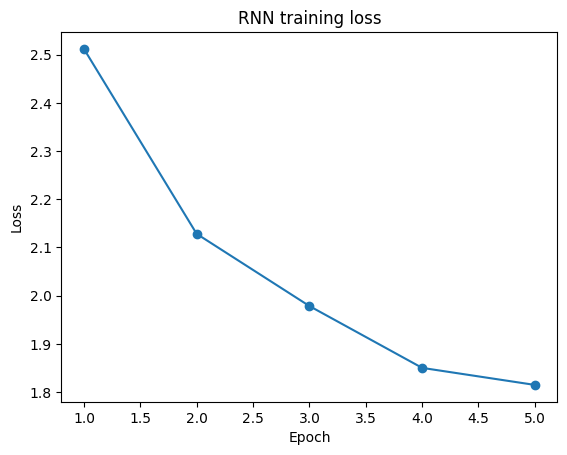

In [5]:
learning_rate = 0.005  # YOUR CODE HERE: between 0.001 and 0.01
epochs, batch_size = 5, 128
loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=learning_rate)

losses = []
for epoch in range(epochs):
    rnn_model.train()
    total_loss = 0.0
    for batch_X, batch_y in loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        # YOUR CODE HERE
        optimizer.zero_grad()
        output = rnn_model(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    losses.append(total_loss / len(loader))
    print(f"Epoch {epoch + 1}/{epochs} - loss {losses[-1]:.4f}")

assert losses[-1] < losses[0] and losses[-1] > 0, "The loss should decrease over the epochs"
plt.plot(range(1, epochs + 1), losses, marker="o"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("RNN training loss"); plt.show()

In [6]:
def generate_text(model, start, length=200, temperature=0.8):
    """Sample characters one by one from the model's predictions."""
    model.eval()
    generated = list(start)
    with torch.no_grad():
        for _ in range(length):
            seq = [char_to_idx.get(c, 0) for c in generated[-seq_length:]]
            seq = [0] * (seq_length - len(seq)) + seq
            logits = model(torch.tensor([seq]).to(device))[0] / temperature
            next_idx = torch.multinomial(torch.softmax(logits, dim=0), 1).item()
            generated.append(idx_to_char[next_idx])
    return "".join(generated)

print(generate_text(rnn_model, "ROMEO: "))

ROMEO: IfI the wene shave sot ear, the erang have counsthere, with me, you thish hea woulf that were of thuir m, go would they were sime the of my courthill pare dis, masurre will sing it my is you ipine in 


---
# Part B – LSTM: sentiment classification

**Use case:** classify movie reviews as positive or negative.

**Data:** IMDB (1 000 training reviews, 200 test reviews, first 100 tokens of each review).

In [7]:
from datasets import load_dataset

def load_imdb():
    ds = load_dataset("stanfordnlp/imdb")
    tr = pd.DataFrame(ds["train"]).sample(n=1000, random_state=42)
    te = pd.DataFrame(ds["test"]).sample(n=200, random_state=42)
    return tr, te

try:
    imdb_train, imdb_test = load_imdb(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("imdb_sample.csv.gz"))
    imdb_train, imdb_test = df[df["split"] == "train"], df[df["split"] == "test"]
imdb_train, imdb_test = imdb_train.reset_index(drop=True), imdb_test.reset_index(drop=True)
print(f"Train: {len(imdb_train)}, test: {len(imdb_test)}")
print(imdb_train.iloc[0]["text"][:300], "-> label", imdb_train.iloc[0]["label"])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Loaded from Hugging Face
Train: 1000, test: 200
Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version of "The Three Amigos", only without any laughs. In order for black comedy to work, it must be outra -> label 0


In [8]:
MAX_LEN = 100

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

def build_vocab(texts, size=5000):
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, _ in counts.most_common(size):
        vocab[word] = len(vocab)
    return vocab

def encode(text, vocab, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokenize(text)][:max_len]
    return ids + [0] * (max_len - len(ids))

imdb_vocab = build_vocab(imdb_train["text"])
X_train = torch.tensor([encode(t, imdb_vocab) for t in imdb_train["text"]])
y_train = torch.tensor(imdb_train["label"].values)
X_test = torch.tensor([encode(t, imdb_vocab) for t in imdb_test["text"]])
y_test = torch.tensor(imdb_test["label"].values)
print(f"Vocabulary: {len(imdb_vocab)} tokens, X_train: {tuple(X_train.shape)}")

Vocabulary: 5002 tokens, X_train: (1000, 100)


### Exercise B.1 – The LSTM classifier

In [9]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.3)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)  # YOUR CODE HERE: nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.dropout(self.embedding(x))
        # YOUR CODE HERE
        output, (hidden, cell) = self.lstm(x)
        return self.fc(hidden[-1])

lstm_model = LSTMClassifier(len(imdb_vocab)).to(device)
print(f"LSTM parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")
assert lstm_model(X_train[:4].to(device)).shape == (4, 2), "The model must return (batch, num_classes)"

LSTM parameters: 353,538


In [10]:
def train_classifier(model, X, y, epochs=3, lr=0.001, batch_size=32):
    """Generic training loop for a classifier (cross-entropy, Adam)."""
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    criterion, optimizer = nn.CrossEntropyLoss(), optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train(); total = 0.0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward(); optimizer.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}/{epochs} – loss {total / len(loader):.4f}")

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(X.to(device)).argmax(dim=1).cpu()
    return (preds == y).float().mean().item()

train_classifier(lstm_model, X_train, y_train, epochs=5)
lstm_accuracy = evaluate(lstm_model, X_test, y_test)
print(f"\nLSTM test accuracy: {lstm_accuracy:.3f}")

Epoch 1/5 – loss 0.6939
Epoch 2/5 – loss 0.6804
Epoch 3/5 – loss 0.6730
Epoch 4/5 – loss 0.6539
Epoch 5/5 – loss 0.6309

LSTM test accuracy: 0.515


---
# Part C – GRU: news classification

**Use case:** classify news articles into World / Sports / Business / Sci-Tech. The GRU has fewer gates than the LSTM, hence fewer parameters.

In [11]:
def load_ag():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=2000, random_state=42), pd.DataFrame(ds["test"]).sample(n=500, random_state=42))

try:
    ag_train, ag_test = load_ag(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("ag_news_sample.csv.gz"))
    ag_train, ag_test = df[df["split"] == "train"], df[df["split"] == "test"]
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

ag_vocab = build_vocab(ag_train["text"])
X_ag_train = torch.tensor([encode(t, ag_vocab, 50) for t in ag_train["text"]])
y_ag_train = torch.tensor(ag_train["label"].values)
X_ag_test = torch.tensor([encode(t, ag_vocab, 50) for t in ag_test["text"]])
y_ag_test = torch.tensor(ag_test["label"].values)
print(f"Train: {tuple(X_ag_train.shape)}, test: {tuple(X_ag_test.shape)}")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loaded from Hugging Face
Train: (2000, 50), test: (500, 50)


### Exercise C.1 – The GRU classifier

In [12]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)  # YOUR CODE HERE: nn.GRU(...)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # YOUR CODE HERE (the GRU returns (output, hidden): no cell state)
        x = self.embedding(x)
        output, hidden = self.gru(x)
        return self.fc(hidden[-1])

gru_model = GRUClassifier(len(ag_vocab)).to(device)
print(f"GRU parameters: {sum(p.numel() for p in gru_model.parameters()):,}")
assert gru_model(X_ag_train[:4].to(device)).shape == (4, 4)

GRU parameters: 345,348


### Exercise C.2 – Train and evaluate the GRU

In [13]:
# YOUR CODE HERE: reuse train_classifier (5-10 epochs) and evaluate
train_classifier(gru_model, X_ag_train, y_ag_train, epochs=8)

gru_model.eval()
with torch.no_grad():
    logits = gru_model(X_ag_test.to(device))
    preds = logits.argmax(dim=1).cpu()
    gru_accuracy = (preds == y_ag_test).float().mean().item()

print(f"\nGRU test accuracy: {gru_accuracy:.3f}")
assert gru_accuracy > 0.5, "A trained GRU should beat 50% on 4 classes"

# Compare the three architectures on the same (vocabulary, embedding, hidden) sizes
for name, cls in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    layer = cls(64, 64, batch_first=True)
    print(f"{name:5}: {sum(p.numel() for p in layer.parameters()):,} parameters in the recurrent layer")

Epoch 1/8 – loss 1.3860
Epoch 2/8 – loss 1.3679
Epoch 3/8 – loss 1.3320
Epoch 4/8 – loss 1.1631
Epoch 5/8 – loss 0.9866
Epoch 6/8 – loss 0.8254
Epoch 7/8 – loss 0.6690
Epoch 8/8 – loss 0.5368

GRU test accuracy: 0.670
RNN  : 8,320 parameters in the recurrent layer
LSTM : 33,280 parameters in the recurrent layer
GRU  : 24,960 parameters in the recurrent layer


---
# Part D – Transformer: named entity recognition

A BERT model fine-tuned for NER (`dslim/bert-base-NER`, trained on CoNLL-2003) is loaded through the Hugging Face `pipeline`. Labels: PER, ORG, LOC, MISC.

In [14]:
from transformers import pipeline

ner_pipeline = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")

sentence = "Apple Inc. was founded by Steve Jobs in Cupertino, California. Tim Cook is the current CEO."
for ent in ner_pipeline(sentence):
    print(f"{ent['word']:20} -> {ent['entity_group']:5} ({ent['score']:.3f})")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Apple Inc            -> ORG   (0.999)
Steve Jobs           -> PER   (0.903)
Cupertino            -> LOC   (0.998)
California           -> LOC   (0.999)
Tim Cook             -> PER   (1.000)


### Exercise D.1 – NER on your own sentences, BERT vs spaCy

In [16]:
import spacy
nlp = spacy.load("en_core_web_sm")

# Write 3 sentences with people, organizations and places (your country, your city, your university...)
my_sentences = [
    "Julia studies Computer Science and Business at EDC Paris Business School in France.",
    "Last summer, Elena visited Madrid and Burgos with her friends from Salamanca.",
    "SNCF operates high-speed TGV trains between Paris and Lyon across Europe."
]
assert all(s != "___" for s in my_sentences)

for s in my_sentences:
    print(f"\n{s}")
    print(" BERT: ", [(e["word"], e["entity_group"]) for e in ner_pipeline(s)])
    print(" spaCy:", [(e.text, e.label_) for e in nlp(s).ents])


Julia studies Computer Science and Business at EDC Paris Business School in France.
 BERT:  [('Julia', 'PER'), ('Computer Science and Business', 'ORG'), ('EDC Paris Business School', 'ORG'), ('France', 'LOC')]
 spaCy: [('Julia', 'ORG'), ('Computer Science and Business', 'ORG'), ('EDC Paris Business School', 'ORG'), ('France', 'GPE')]

Last summer, Elena visited Madrid and Burgos with her friends from Salamanca.
 BERT:  [('Elena', 'PER'), ('Madrid', 'LOC'), ('B', 'LOC'), ('##urgos', 'LOC'), ('Salamanca', 'LOC')]
 spaCy: [('Last summer', 'DATE'), ('Elena', 'ORG'), ('Madrid', 'GPE'), ('Burgos', 'GPE'), ('Salamanca', 'PERSON')]

SNCF operates high-speed TGV trains between Paris and Lyon across Europe.
 BERT:  [('SNCF', 'ORG'), ('TG', 'MISC'), ('Paris', 'LOC'), ('Lyon', 'LOC'), ('Europe', 'LOC')]
 spaCy: [('TGV', 'ORG'), ('Paris', 'GPE'), ('Lyon', 'ORG'), ('Europe', 'LOC')]


### Question D.2 (written)

Compare the two models on your sentences: which entities are found by both, by one only, with a wrong type? Which model would you trust more, and for which kind of text?

<!-- ANSWER lab5-D2 -->
**Your answer:**

Both models found most of the main entities, though BERT uses CoNLL-2003 tags (PER, ORG, LOC, MISC) while spaCy uses OntoNotes tags (PERSON, ORG, GPE, LOC).
Only BERT detected SNCF (ORG), whereas only spaCy extracted Last summer (DATE), since BERT's label set does not cover dates. Regarding errors, both models wrongly labeled the capitalized academic subjects Computer Science and Business as ORG, while spaCy struggled significantly with non-English names—misclassifying Julia and Elena as ORG, Salamanca as PERSON, and Lyon as ORG—whereas BERT correctly classified all people and locations, only exhibiting minor WordPiece subword splitting on Burgos ('B', '##urgos') and TGV ('TG').
I would trust BERT much more for complex texts because its bidirectional Transformer architecture accurately disambiguates unfamiliar names, while spaCy is better suited for fast, lightweight processing of large volumes of standard English text where speed and extra categories like dates or quantities matter more than edge-case accuracy.
<!-- END ANSWER -->

---
# Part E – Large language models through an API

Two free options:
- **Mistral AI** (default): create an account on https://console.mistral.ai/ (free *Experiment* plan, phone verification required) and create an API key.
- **Hugging Face Inference**: use the access token of your Hugging Face account (https://huggingface.co/settings/tokens).

The key is typed in the cell below and kept in memory only. **Never paste a key in a notebook or commit it to GitHub**: keys found in public repositories are revoked within minutes.

In [25]:
from getpass import getpass

PROVIDER = "huggingface"      # "mistral" or "huggingface"

def get_api_key(name):
    """Key from Colab secrets, from an environment variable, or typed by the user."""
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        return getpass(f"{name} (leave empty to skip Part E): ")
    except Exception:
        return ""

API_KEY = get_api_key("MISTRAL_API_KEY" if PROVIDER == "mistral" else "HF_TOKEN")
print("Key provided" if API_KEY else "No key: the LLM cells will be skipped")

HF_TOKEN (leave empty to skip Part E): ··········
Key provided


In [30]:
import requests

def query_llm(prompt, max_tokens=200, temperature=0.0):
    """Send a single-turn chat prompt to the selected provider and return the answer text."""
    if not API_KEY:
        return "(no API key)"
    if PROVIDER == "mistral":
        url, model = "https://api.mistral.ai/v1/chat/completions", "mistral-small-latest"
    else:
        url, model = "https://router.huggingface.co/v1/chat/completions", "Qwen/Qwen3-4B-Instruct-2507"
    payload = {"model": model, "messages": [{"role": "user", "content": prompt}], "max_tokens": max_tokens, "temperature": temperature}
    for attempt in range(5):
        r = requests.post(url, headers={"Authorization": f"Bearer {API_KEY}"}, json=payload, timeout=60)
        if r.status_code == 429:            # rate limit of the free plan: wait and retry
            time.sleep(2 * (attempt + 1)); continue
        if r.status_code != 200:
            return f"Error {r.status_code}: {r.text[:200]}"
        return r.json()["choices"][0]["message"]["content"].strip()
    return "Error: rate limit"

print(query_llm("Explain what NLP is in one sentence."))

Error 400: {"error":{"message":"The requested model 'Qwen/Qwen3-4B-Instruct-2507' is not supported by any provider you have enabled.","type":"invalid_request_error","param":"model","code":"model_not_supported"}}


### Exercise E.1 – Zero-shot sentiment vs the LSTM

Ask the LLM to classify 20 IMDB test reviews and compare its accuracy with the LSTM of Part B.

In [24]:
def llm_sentiment(review):
    prompt = f"""Classify the sentiment of this movie review as positive or negative. Answer with one word only.

Review: {review[:1500]}

Sentiment:"""
    answer = query_llm(prompt, max_tokens=5).lower()
    return 1 if "positive" in answer else 0

sample = imdb_test.head(20)
if API_KEY:
    llm_preds = [llm_sentiment(review) for review in sample['text']]  # YOUR CODE HERE: list of llm_sentiment(review) for the 20 reviews
    llm_accuracy = np.mean(np.array(llm_preds) == sample['label'].values)  # YOUR CODE HERE: share of correct predictions
    lstm_preds = lstm_model(X_test[:20].to(device)).argmax(dim=1).cpu().numpy()
    print(f"LLM accuracy on 20 reviews:  {llm_accuracy:.2f}")
    print(f"LSTM accuracy on 20 reviews: {np.mean(lstm_preds == sample['label'].values):.2f}")
else:
    print("Skipped (no API key)")

LLM accuracy on 20 reviews:  0.55
LSTM accuracy on 20 reviews: 0.40


### Exercise E.2 – Summarization and structured extraction

In [20]:
nike_df = pd.read_csv(local_file("NikeProductDescriptions.csv"))
description = nike_df.iloc[3]["Product Description"]
print(description, "\n")

if API_KEY:
    print("Summary:", query_llm(f"Summarize this product description in one sentence:\n\n{description}", max_tokens=60), "\n")

    # Extraction: ask for a JSON object with the keys product_type, materials (list), target_user, key_benefits (list)
    prompt = f"""Extract information from the product description below and return ONLY a valid JSON object (no markdown, no explanation) with these exact keys:
- "product_type": string
- "materials": list of strings
- "target_user": string
- "key_benefits": list of strings

Product description:
{description}"""  # YOUR CODE HERE: write the extraction prompt
    answer = query_llm(prompt, max_tokens=200)
    print("Extraction:", answer)
    try:
        info = json.loads(answer.strip().strip("`").removeprefix("json"))
        print("\nParsed keys:", list(info.keys()))
    except Exception:
        print("\nThe answer is not valid JSON: adjust the prompt (ask for JSON only, no explanation)")
else:
    print("Skipped (no API key)")

The celebrations just keep coming. Unbox the AF-1 for a fireside feel and a whole lotta style. The joyful take on the hoops icon pairs crisp leather with seasonally perfect prints and colours. And don't worry—even if you've been naughty, you're gonna look nice. 

Summary: Error 401: {"detail":"Invalid API Key"}
 

Extraction: Error 401: {"detail":"Invalid API Key"}


The answer is not valid JSON: adjust the prompt (ask for JSON only, no explanation)


---
# Final questions

### Question F.1 (written)

Report the parameter counts printed in Parts A-C. Why does an LSTM layer have more parameters than a GRU layer, and a GRU more than a simple RNN? (think about the gates)

<!-- ANSWER lab5-F1 -->
**Your answer:**

In Parts A–C, the full models contain 30,074 parameters (Part A RNN), 353,538 parameters (Part B LSTM), and 345,348 parameters (Part C GRU), where the total counts differ largely due to each dataset's vocabulary size in the embedding layer.
When comparing only the recurrent layers with identical dimensions at the end of Exercise C.2, the parameter counts are 8,320 for RNN, 24,960 for GRU, and 33,280 for LSTM.
An LSTM layer has more parameters than a GRU layer and a GRU more than a simple RNN because each internal gate requires its own independent set of input-to-hidden and hidden-to-hidden weight matrices and biases: a simple RNN has no gates, a GRU has 2 gates plus 1 candidate state calculation , and an LSTM has 3 gates plus 1 candidate memory calculation.


<!-- END ANSWER -->

### Question F.2 (written)

Why does an LSTM handle long reviews better than a vanilla RNN? Explain the vanishing gradient problem in a few sentences.

<!-- ANSWER lab5-F2 -->
**Your answer:**

A simple RNN struggles with long reviews because of the vanishing gradient problem: as the model reads word by word, the learning signal shrinks exponentially as it travels backward through many steps, so the network effectively "forgets" words from the beginning of the review.
An LSTM solves this by adding a separate memory cell controlled by three gates (forget, input, and output gates). These gates act like a direct memory pathway that lets the model choose what important information to keep and carry forward without weakening the learning signal, allowing it to remember key details from early in a long review.
<!-- END ANSWER -->

### Question F.3 (written)

From your experiments:
1. What can the LLM do that the LSTM/GRU cannot?
2. What are the drawbacks of calling an LLM API? (cost, latency, privacy, reproducibility...)
3. When would you still choose a small trained model over an LLM?

<!-- ANSWER lab5-F3 -->
**Your answer:**

1- The trained LSTM and GRU models can only do one specific task they were trained for using fixed, short text lengths and thousands of labeled examples. In contrast, an LLM is already pre-trained on massive amounts of text and can do many different tasks without any extra training just by changing the prompt. In Part E, the exact same LLM classified movie reviews, summarized a Nike product description in one sentence, and extracted structured JSON data—all while reading much longer texts.

2- Calling an LLM API has some drawbacks:
Cost: You pay per token/request, which gets expensive at scale, while a local model is free to run once trained.
Speed: Sending requests over the internet to a huge model takes seconds (and can hit rate limits), whereas a small local model runs in milliseconds.
Privacy: You have to send your text to an external company's servers, which is risky for confidential or personal data.
Reliability and reproducibility: APIs can fail, change over time, or give slightly different answers to the same prompt.
<!-- END ANSWER -->

---
## Summary

| Model | Strength | Weakness | Typical use |
|-------|----------|----------|-------------|
| RNN | Simple, fast | Vanishing gradients, short memory | Short sequences, teaching |
| LSTM | Long-term memory | More parameters | Text classification, tagging |
| GRU | Fewer parameters than LSTM | Slightly less expressive | When speed matters |
| Transformer (BERT) | Contextual, parallel training | Needs fine-tuning data, heavier | NER, classification, QA |
| LLM (API) | Zero-shot, generation | Cost, latency, privacy | Prototyping, open-ended tasks |

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.